# Thí nghiệm 3 · Kết hợp Random Forest và Gradient Boosting

**Luồng chạy**  Dự đoán RF C và GB C đã lưu → Đối chiếu giờ đủ lịch sử → Lấy trung bình 50/50 → Chấm từng mô hình và mô hình kết hợp → Xuất kết quả.

Chạy thí nghiệm 2 trước để có dự đoán trên validation. Trọng số 50/50 được cố định trước khi xem điểm. Dữ liệu thời tiết cùng giờ và các quan sát lưu lượng trước giờ dự đoán được giả định có sẵn.

In [1]:
import hashlib
import json
from pathlib import Path
import sys

start = Path.cwd().resolve()
project = next(path for path in (start, *start.parents) if (path / "src" / "data.py").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd

from src.data import DATA_PATH, load_hourly_splits
from src.evaluation import clip_prediction, regression_metrics
from src.features import add_history_features, add_time_features, has_history

experiment = project / "experiments" / "17-11-2026_Huy_ConfigC" / "03_ensemble"
source = experiment.parent / "02_models_bc" / "outputs" / "validation_predictions.csv"
data_path = DATA_PATH if DATA_PATH.is_file() else project / "files" / "Metro_Interstate_Traffic_Volume.csv.gz"
data_params = {"mask_stuck_temp": False, "complete_holidays": False}
if not source.is_file():
    raise FileNotFoundError(f"Chạy notebook thí nghiệm 2 để tạo {source.name}.")

In [2]:
splits = load_hourly_splits(data_path, **data_params)
chronological = pd.concat(
    [splits["train"], splits["validation"]], ignore_index=True,
)
timestamps = chronological["date_time"]
if not timestamps.is_unique or not timestamps.is_monotonic_increasing or timestamps.isna().any():
    raise ValueError("Train và validation phải có timestamp duy nhất, đầy đủ và tăng dần.")
history = add_history_features(add_time_features(chronological))
validation_hours = pd.Index(splits["validation"]["date_time"])
eligible = history.loc[
    history["date_time"].isin(validation_hours) & has_history(history),
    ["date_time", "traffic_volume", "is_rush_hour"],
].set_index("date_time")

predictions = pd.read_csv(source, parse_dates=["date_time"]).set_index("date_time")
predictions = predictions[["traffic_volume", "is_rush_hour", "rf_c", "gb_c"]].copy()
if not predictions.index.is_unique:
    raise ValueError("Dự đoán từ thí nghiệm 2 có timestamp trùng lặp.")
pd.testing.assert_index_equal(predictions.index, eligible.index, exact=True)
pd.testing.assert_series_equal(predictions["traffic_volume"], eligible["traffic_volume"], check_dtype=False)
pd.testing.assert_series_equal(predictions["is_rush_hour"], eligible["is_rush_hour"], check_dtype=False)
if predictions[["rf_c", "gb_c"]].isna().any().any():
    raise ValueError("Dự đoán RF C và GB C phải đầy đủ.")
print(f"Khớp {len(eligible):,}/{len(validation_hours):,} giờ validation, lưu lượng thực và cờ giờ cao điểm.")

Khớp 6,050/6,086 giờ validation, lưu lượng thực và cờ giờ cao điểm.


In [3]:
predictions["rf_c"] = clip_prediction(predictions["rf_c"])
predictions["gb_c"] = clip_prediction(predictions["gb_c"])
predictions["blend_c"] = 0.5 * predictions["rf_c"] + 0.5 * predictions["gb_c"]

models = {
    "RF C": "rf_c",
    "GB C": "gb_c",
    "RF + GB C (50/50)": "blend_c",
}
metrics = pd.DataFrame.from_dict(
    {model: regression_metrics(predictions["traffic_volume"], predictions[column])
     for model, column in models.items()},
    orient="index",
).rename_axis("model")
metrics.insert(0, "n_hours", len(predictions))

is_peak = eligible["is_rush_hour"].eq(1)
slices = []
for group, mask in {"Giờ cao điểm": is_peak, "Ngoài cao điểm": ~is_peak}.items():
    subset = predictions.loc[mask]
    for model, column in models.items():
        scores = regression_metrics(subset["traffic_volume"], subset[column])
        slices.append({"group": group, "model": model, "n_hours": len(subset), **scores})
slice_metrics = pd.DataFrame(slices)

blend = metrics.loc["RF + GB C (50/50)"]
comparison = metrics.loc[["RF C", "GB C"], ["MAE", "RMSE", "R2"]].rsub(blend[["MAE", "RMSE", "R2"]])
comparison.columns = ["delta_MAE", "delta_RMSE", "delta_R2"]
display(metrics.round(4))
display(slice_metrics.round(4))
display(comparison.round(4))

,n_hours,MAE,RMSE,R2
model,,,,
RF C,6050,215.1907,354.3529,0.9675
GB C,6050,229.2764,366.1250,0.9653
RF + GB C (50/50),6050,216.9071,353.0560,0.9677


,group,model,n_hours,MAE,RMSE,R2
0,Giờ cao điểm,RF C,1080,303.0411,494.3438,0.7101
1,Giờ cao điểm,GB C,1080,329.9160,532.1275,0.6641
2,Giờ cao điểm,RF + GB C (50/50),1080,310.0638,504.0894,0.6986
3,Ngoài cao điểm,RF C,4970,196.1005,315.8293,0.9666
4,Ngoài cao điểm,GB C,4970,207.4070,318.8179,0.9659
5,Ngoài cao điểm,RF + GB C (50/50),4970,196.6638,310.6717,0.9677


,delta_MAE,delta_RMSE,delta_R2
model,,,
RF C,1.7164,-1.2969,0.0002
GB C,-12.3692,-13.0689,0.0024


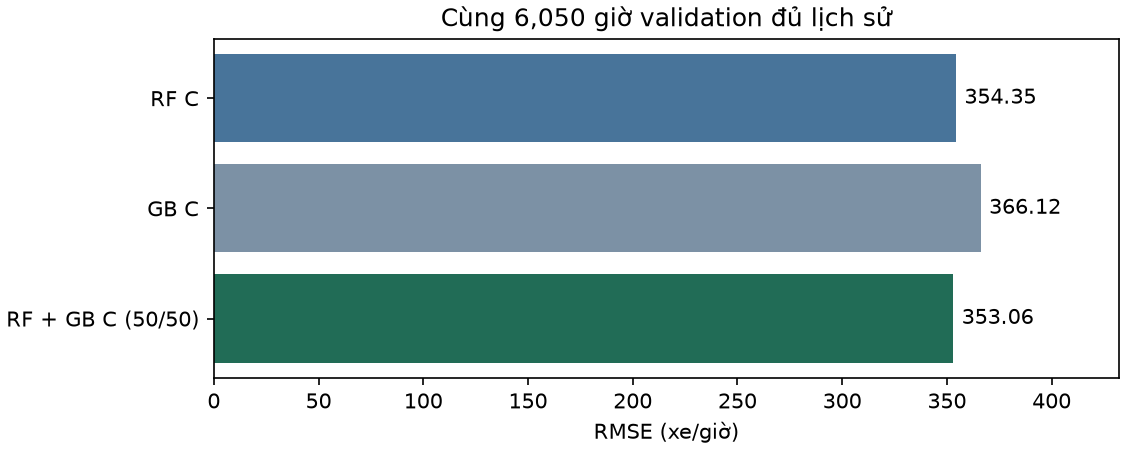

In [4]:
outputs = experiment / "outputs"
figures = experiment / "figures"
outputs.mkdir(exist_ok=True)
figures.mkdir(exist_ok=True)
predictions.to_csv(outputs / "validation_predictions.csv")
metrics.to_csv(outputs / "validation_metrics.csv")
slice_metrics.to_csv(outputs / "validation_slices.csv", index=False)
comparison.to_csv(outputs / "validation_deltas.csv")
with source.open("rb") as stream:
    source_hash = hashlib.file_digest(stream, "sha256").hexdigest()
with data_path.open("rb") as stream:
    data_hash = hashlib.file_digest(stream, "sha256").hexdigest()
run_config = {
    "method": "fixed arithmetic mean of nonnegative RF C and GB C predictions",
    "weights": {"RF C": 0.5, "GB C": 0.5},
    "dataset": data_path.relative_to(project).as_posix(),
    "dataset_sha256": data_hash,
    "source_predictions": source.relative_to(project).as_posix(),
    "source_predictions_sha256": source_hash,
    "data_params": data_params,
    "validation": {
        "n_total": len(validation_hours),
        "n_eligible": len(eligible),
        "first": str(eligible.index[0]),
        "last": str(eligible.index[-1]),
        "verified_timestamp_target_and_peak_flag": True,
    },
}
(outputs / "run_config.json").write_text(
    json.dumps(run_config, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
)

fig, ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
bars = ax.barh(metrics.index, metrics["RMSE"], color=["#48749A", "#7C91A5", "#216C56"])
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_xlim(0, metrics["RMSE"].max() * 1.18)
ax.invert_yaxis()
ax.set_xlabel("RMSE (xe/giờ)")
ax.set_title(f"Cùng {len(predictions):,} giờ validation đủ lịch sử")
figure = figures / "validation_rmse.png"
fig.savefig(figure, dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))

In [5]:
best_model = metrics.loc[["RF C", "GB C"], "RMSE"].idxmin()
delta_rmse = comparison.loc[best_model, "delta_RMSE"]
print(f"So với thành phần tốt nhất ({best_model}), RMSE của tổ hợp thay đổi {delta_rmse:+.2f} xe/giờ.")
if delta_rmse < 0:
    print("Có thể thử trọng số học từ dự đoán ngoài fold trên train bằng TimeSeriesSplit, rồi chấm lại trên cùng validation.")
else:
    print("Tổ hợp 50/50 chưa giảm RMSE so với thành phần tốt nhất trên validation.")

So với thành phần tốt nhất (RF C), RMSE của tổ hợp thay đổi -1.30 xe/giờ.
Có thể thử trọng số học từ dự đoán ngoài fold trên train bằng TimeSeriesSplit, rồi chấm lại trên cùng validation.
